<a href="https://colab.research.google.com/github/Darioldeveloper-dev/CSC4110-G01/blob/main/G01_U3_1_linear_gd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Machine Learning
## Group G01: Student Performance Factors
### Task 3.1: Linear Regression and Gradient Descent

- **Registration number:** COM/0066/23
- ** owner:** Elisha Eddie (Member 3)
- **Module:** 4

**Contents**
1. Setup and data loading
2. Simple linear regression
3. Multiple linear regression
4. Gradient descent from scratch
5. Written answer

In [ ]:
# Mount Drive, import libraries and load the cleaned data from Task 2.2
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df_clean = pd.read_csv("/content/drive/MyDrive/CSC4110_G01/data/clean_students.csv")
out = "/content/drive/MyDrive/CSC4110_G01/outputs/"

# Recreate the same 80/20 split as Task 2.2 (same seed, same result)
X = df_clean.drop(columns=['Exam_Score', 'high_score'])
y = df_clean['Exam_Score']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Fit a line using Attendance only (double brackets keep it a table, as scikit-learn expects)
lr_simple = LinearRegression().fit(X_train[['Attendance']], y_train)

# Read off the intercept b0 and slope b1
b0 = lr_simple.intercept_
b1 = lr_simple.coef_[0]
print(f"Fitted equation: y_hat = {b0:.4f} + {b1:.4f} * Attendance")

Fitted equation: y_hat = 51.4702 + 0.1971 * Attendance


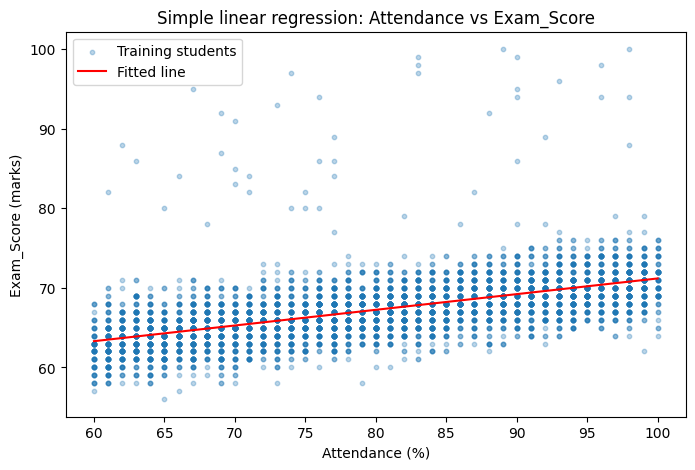

In [ ]:
# Scatter of the training points with the fitted line on top
plt.figure(figsize=(8, 5))
plt.scatter(X_train['Attendance'], y_train, alpha=0.3, s=10, label='Training students')
line_x = pd.DataFrame({'Attendance': [60, 100]})
plt.plot(line_x['Attendance'], lr_simple.predict(line_x), color='red', label='Fitted line')
plt.title('Simple linear regression: Attendance vs Exam_Score')
plt.xlabel('Attendance (%)')
plt.ylabel('Exam_Score (marks)')
plt.legend()
plt.savefig(out + 'simple_fit.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
lr_simple.score(X_test[['Attendance']], y_test)

0.3476191017603256

In [ ]:
# Take the first test row and predict by hand using the equation
x0 = X_test['Attendance'].iloc[0]
y0 = y_test.iloc[0]
pred_by_hand = b0 + b1 * x0
residual = y0 - pred_by_hand
print("Attendance:", x0, "| actual:", y0)
print("Predicted by hand:", round(pred_by_hand, 4), "| residual:", round(residual, 4))

# Confirm with scikit-learn
pred_code = lr_simple.predict(X_test[['Attendance']].iloc[[0]])[0]
print("Predicted by scikit-learn:", round(pred_code, 4))

Attendance: 71 | actual: 65
Predicted by hand: 65.4658 | residual: -0.4658
Predicted by scikit-learn: 65.4658


### Simple Linear Regression Interpretation (`Attendance` → `Exam_Score`)

**1. Model Parameters and Prediction Analysis:**
- **Slope ($b_1 = 0.197$):** Every additional percentage point of attendance is associated with roughly `0.2` extra exam marks on average; increasing attendance from `60%` to `100%` lifts the predicted score by `7.88` marks (from `63.30` to `71.18`).
- **Intercept ($b_0 = 51.47$):** Represents the mathematical baseline score at `0%` attendance. Because no student in the dataset has attendance below `60%`, this value is a pure extrapolation—necessary to anchor the regression line mathematically, but not a meaningful claim about real students.
- **Residual ($-0.47$):** Since $\text{Residual} = \text{Actual} - \text{Predicted}$, a negative residual shows the model slightly over-predicted this student's exam score by nearly half a mark (their actual mark fell just below the regression line).
- **Correlation vs. Causation:** This positive slope captures a statistical association rather than proof of cause and effect—the observational data alone cannot prove that increasing attendance directly causes higher exam marks.

**2. Code & Conceptual Check:**
- **Why `X_train[['Attendance']]` Uses Double Square Brackets:** Single brackets (`X_train['Attendance']`) return a 1-dimensional pandas `Series`, whereas scikit-learn's `.fit()` requires a 2-dimensional feature matrix (`DataFrame` of shape `(n_samples, 1)`), which double brackets provide.
- **Interpreting a $+3$ Residual:** Because $\text{Residual} = \text{Actual} - \text{Predicted} = +3$, the student's actual score was `3` marks higher than predicted—meaning the model's prediction was **too low**.
- **Meaning of a Negative $b_1$:** A negative slope would mean that higher attendance is associated with *lower* predicted exam scores on average (each extra percentage point of attendance would correspond to a drop in expected marks).

In [ ]:
# Import the scaler and the error measures
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fit the scaler on the training set only, then scale both sets
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fit the multiple linear regression on all 22 scaled features
lr_multi = LinearRegression().fit(X_train_scaled, y_train)

# Predict on both sets
pred_train = lr_multi.predict(X_train_scaled)
pred_test = lr_multi.predict(X_test_scaled)

In [ ]:
# Function that returns the four regression measures for one set of predictions
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'MSE': mse,
            'RMSE': float(np.sqrt(mse)),
            'R2': r2_score(y_true, y_pred)}

# Store train and test results in the dictionary the brief asks for
metrics_multi = {'train': regression_metrics(y_train, pred_train),
                 'test': regression_metrics(y_test, pred_test)}
print(pd.DataFrame(metrics_multi).round(4))

       train    test
MAE   0.4956  0.4451
MSE   4.3419  3.2341
RMSE  2.0837  1.7984
R2    0.7175  0.7712


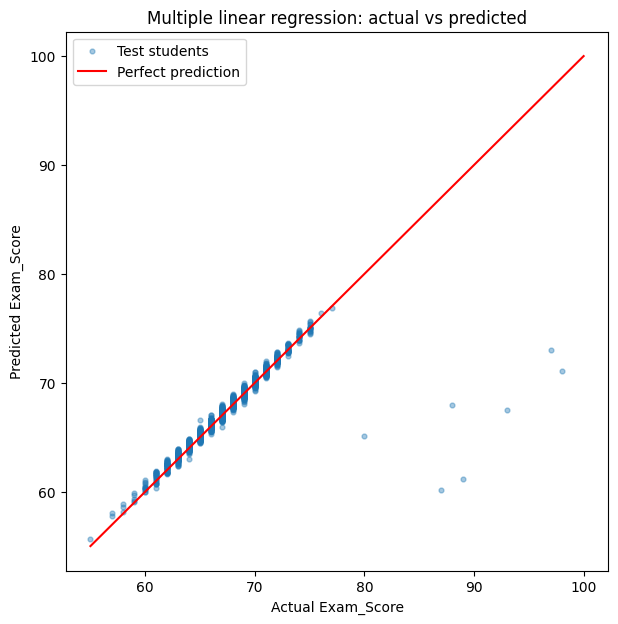

In [ ]:
# Scatter of actual vs predicted test scores, with the perfect-prediction diagonal
plt.figure(figsize=(7, 7))
plt.scatter(y_test, pred_test, alpha=0.4, s=12, label='Test students')
plt.plot([55, 100], [55, 100], color='red', label='Perfect prediction')
plt.title('Multiple linear regression: actual vs predicted')
plt.xlabel('Actual Exam_Score')
plt.ylabel('Predicted Exam_Score')
plt.legend()
plt.savefig(out + 'actual_vs_pred.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Rank the scaled coefficients by size, ignoring the sign
coefs = pd.Series(lr_multi.coef_, index=X_train.columns)
top5 = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(5)
print(top5.round(4))

Attendance              2.1391
Hours_Studied           1.4369
Access_to_Resources     0.7308
Previous_Scores         0.7070
Parental_Involvement    0.6996
dtype: float64


### Actionability of Key Predictors for School Intervention

**Directly Actionable Factors:** Factors that a school can actively influence through daily policies and structured support programs:
- **`Attendance` and `Hours_Studied` (Yes):** Schools can directly improve both by monitoring attendance closely, running supervised study periods, and establishing structured homework routines.
- **`Access_to_Resources` (Largely Yes):** Schools can bridge resource gaps directly by supplying textbooks, opening computer labs, and providing reliable on-campus internet access.

**Partially Actionable Factors:** Factors where school outreach helps, but external home dynamics limit full control:
- **`Parental_Involvement` (Partly):** Schools can encourage engagement through regular parent-teacher meetings and proactive communication, though they cannot directly control support levels inside the home.

**Non-Actionable Historical Factors:** Factors that cannot be altered retroactively, though they serve as early warning indicators:
- **`Previous_Scores` (No):** Past academic results cannot be changed, though identifying students with low prior scores allows schools to target remedial tutoring to improve future performance.

Therefore, Attendance and Hours_Studied are the strongest and most actionable levers; Access_to_Resources and Parental_Involvement are weaker but also worth acting on

In [ ]:
# Scale Attendance using the training set only (mean 0, standard deviation 1)
att_scaler = StandardScaler().fit(X_train[['Attendance']])
x_s = att_scaler.transform(X_train[['Attendance']])[:, 0]   # 1-D array of scaled values
y_s = y_train.values                                        # 1-D array of actual scores

In [ ]:
# Cost: half the mean squared error between predictions and actual scores
def cost(b0, b1, x, y):
    errors = b0 + b1 * x - y
    return (errors ** 2).sum() / (2 * len(x))

# Gradient descent for the simple model, starting from b0 = b1 = 0
def gradient_descent(x, y, lr, iterations):
    b0, b1 = 0.0, 0.0
    costs = []
    for i in range(iterations):
        errors = b0 + b1 * x - y                # prediction minus actual
        costs.append(cost(b0, b1, x, y))        # record the cost before this update
        grad_b0 = errors.mean()                 # slope of the cost along b0
        grad_b1 = (errors * x).mean()           # slope of the cost along b1
        b0 = b0 - lr * grad_b0                  # step downhill
        b1 = b1 - lr * grad_b1
    return b0, b1, costs

In [ ]:
# Run 1000 iterations for each learning rate and store the cost histories
cost_history = {}
final_params = {}
for lr in [0.001, 0.01, 0.1]:
    b0, b1, costs = gradient_descent(x_s, y_s, lr, 1000)
    cost_history[lr] = costs
    final_params[lr] = (b0, b1)
    print(f"lr = {lr}: final cost = {costs[-1]:.4f}, b0 = {b0:.5f}, b1 = {b1:.5f}")

lr = 0.001: final cost = 311.4740, b0 = 42.50032, b1 = 1.43562
lr = 0.01: final cost = 5.1067, b0 = 67.21205, b1 = 2.27036
lr = 0.1: final cost = 5.1067, b0 = 67.21495, b1 = 2.27046


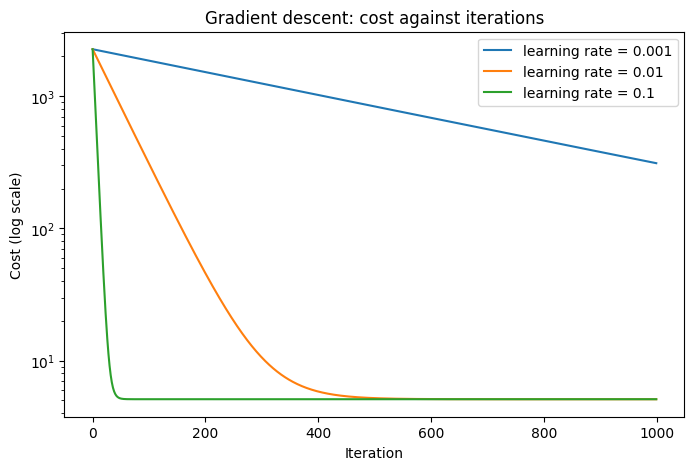

In [ ]:
# Cost against iteration for each learning rate (log scale because the costs span a huge range)
plt.figure(figsize=(8, 5))
for lr, costs in cost_history.items():
    plt.plot(costs, label=f'learning rate = {lr}')
plt.yscale('log')
plt.title('Gradient descent: cost against iterations')
plt.xlabel('Iteration')
plt.ylabel('Cost (log scale)')
plt.legend()
plt.savefig(out + 'gd_cost.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Final values from the learning rate that converged fastest
b0_gd, b1_gd = final_params[0.1]

# scikit-learn fitted on the same scaled feature
lr_scaled = LinearRegression().fit(x_s.reshape(-1, 1), y_s)
print(f"Gradient descent: b0 = {b0_gd:.5f}, b1 = {b1_gd:.5f}")
print(f"scikit-learn    : b0 = {lr_scaled.intercept_:.5f}, b1 = {lr_scaled.coef_[0]:.5f}")

# Self-check: both methods agree
assert np.isclose(b0_gd, lr_scaled.intercept_, atol=1e-3)
assert np.isclose(b1_gd, lr_scaled.coef_[0], atol=1e-3)
print("Gradient descent matches scikit-learn")

Gradient descent: b0 = 67.21495, b1 = 2.27046
scikit-learn    : b0 = 67.21495, b1 = 2.27046
Gradient descent matches scikit-learn


In [3]:
# List every variable whose name contains "cost"
print([name for name in globals() if 'cost' in name.lower()])

[]
[]


### Gradient Descent Convergence and Learning Rate Analysis

**1. Learning Rate Comparison & Convergence:**
- **`lr = 0.001` (Too Slow):** Over `1,000` iterations, the cost dropped only from `2,266.6` to `311.47` because the update steps were too tiny to reach the bottom within the iteration budget.
- **`lr = 0.01` (Moderate):** Converged steadily to the minimum cost of `5.1067` after roughly `730` iterations.
- **`lr = 0.1` (Fast & Efficient):** Reached the exact same minimum cost of `5.1067` in only about `70` iterations—roughly ten times faster than `lr = 0.01` without overshooting.
- **Why $b_0$ and $b_1$ Match `scikit-learn`:** Because Mean Squared Error (MSE) forms a smooth, strictly convex "bowl" with a single global minimum and no local traps, both iterative gradient descent (given enough steps) and `scikit-learn`'s exact analytical solver converge to the exact same optimal parameters.

**2. Conceptual Check:**
- **Why $b_0$ Equals the Mean of the Training Scores:** When the input feature is standardized to have a mean of `0` ($\bar{x} = 0$), the line of best fit must pass through the center of the data $(\bar{x}, \bar{y}) = (0, \bar{y})$, which forces the intercept $b_0$ to equal the sample mean of the training scores ($\bar{y}$).
- **Why the `lr = 0.1` Curve Appears as a Nearly Vertical Drop:** Because `0.1` takes large steps down the steepest part of the cost bowl right at the start, nearly all of the error reduction happens within the first ~70 iterations; plotted across a `1,000`-iteration horizontal axis, that rapid drop compresses into a nearly vertical line on the far left before flattening at `5.1067`.
- **What Went Wrong If Cost Increases Each Iteration:** The **learning rate is too large**, causing gradient descent to take oversized steps that overshoot the minimum and bounce higher and higher up the opposite walls of the cost bowl (divergence).